In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from pathlib import Path
import sys
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


In [2]:
import pandas as pd
import openai
print(pd.__version__)

print(openai.__version__)


2.3.3
2.46.0


In [3]:
# Navigiert vom Notebook-Ordner eine Ebene nach oben zum Projekt-Root
root_dir = Path.cwd().parent
if str(root_dir) not in sys.path:
    sys.path.append(str(root_dir))

print(root_dir)

/Users/msyl16/Desktop/soylu_mustafa_spezialisierungsmodul


In [4]:
from src import data_preprocessing, code_directory_analyzer

# Ergebnisse und Evaluation
* **Dieses Notebook orientiert sich an Kapitel 6 und 7 aus der PDF**

### Datenimport

In [5]:
df_projects_before = pd.read_parquet("../data/parquet/df_projects_before.parquet")
df_filtered = pd.read_parquet("../data/parquet/df_filtered.parquet") # gefilterete Daten: ca.70k Daten
df_semgrep_baseline = pd.read_parquet("../data/parquet/df_semgrep_baseline.parquet") # Semgrep Baseline
df_semgrep_code_completion = pd.read_parquet("../data/parquet/df_semgrep_code_completion.parquet") # Semgrep CC
df_sample = pd.read_parquet("../data/parquet/df_sample.parquet") # Sample: 200 Daten

df_manuelle_annotation = pd.read_csv("../data/Excel/manuelle_annotation.csv")  # manuelle Annotation

## Kapitel 6.1

In [6]:
## KPI Anzahl Daten
df_projects_before.shape, df_filtered.shape, 

((110535, 31), (76622, 16))

### Abbildung 6.1

<Axes: xlabel='Anzahl'>

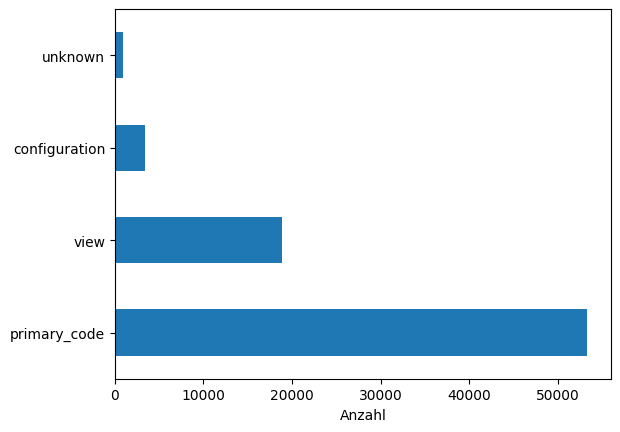

In [7]:
(
    df_filtered.item_type
    .value_counts()
    .plot
    .barh(
        ylabel="",
        xlabel="Anzahl",
    )
)

In [8]:
(
    df_filtered.item_type
    .value_counts(normalize=True)
)

item_type
primary_code     0.695597
view             0.246861
configuration    0.044870
unknown          0.012673
Name: proportion, dtype: float64

### Abbildung 6.2

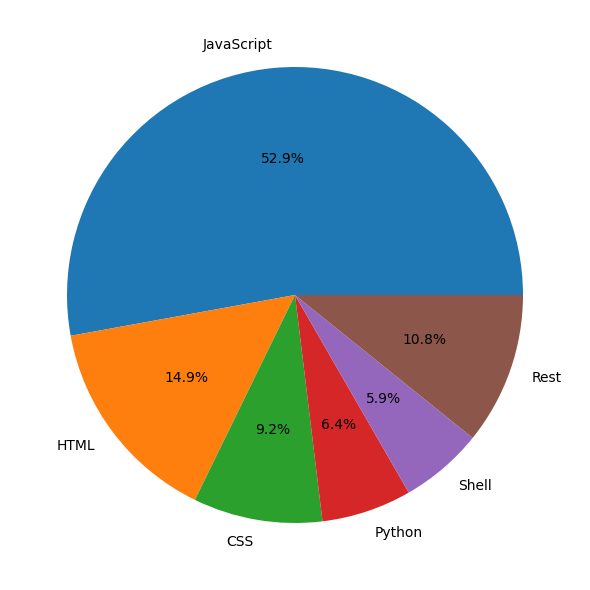

In [9]:
# Prozentuale Verteilung der Technologiesprachen
count_languages = (
    df_filtered
    .programming_language
    .value_counts(normalize=True)
)

# TOP 5 + Rest summieren

top_5 = count_languages.head(5)
rest = count_languages.iloc[5:].sum()

if rest > 0:
    plot_data = top_5.copy()
    plot_data["Rest"] = rest
else:
    plot_data = top_5

# Einfach plotten mit pie()
fig, ax = plt.subplots(figsize=(8, 6))
(
    plot_data
    .plot
    .pie(
        autopct="%1.1f%%",
        ax=ax,
        ylabel=""
    )
)
plt.tight_layout()
plt.show()

### Abbildung 6.3

/opt/homebrew/lib/python3.14/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


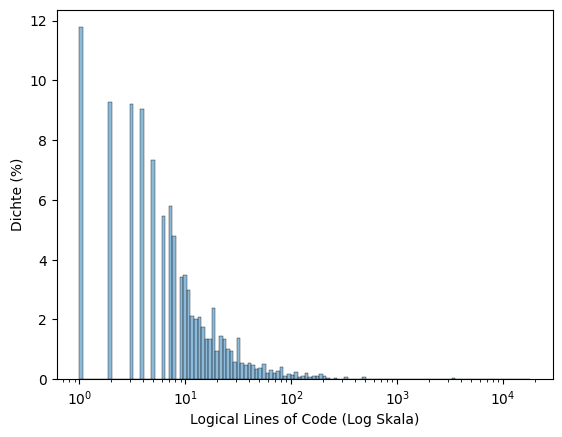

In [10]:
df_primary_code = df_filtered[df_filtered["item_type"] == "primary_code"]

sns.histplot(
    data=df_primary_code,
    x="logical_lines_of_code",
    log_scale=True,
    kde=True,
    stat="percent",
)

# plt.title("Verteilung von LLOC in Source Code (n=53.298)") --> direkt in Latex einbauen
plt.xlabel("Logical Lines of Code (Log Skala)")
plt.ylabel("Dichte (%)")
plt.show()

## Kapitel 6.2 & 6.3

Wie viele Sicherheitslücken gibt es tatsächlich in der Stichprobe?

In [11]:
print(f"Gefundene Sicherheitslücken: {df_manuelle_annotation.Vorhanden.value_counts()[1]}")
print(f"Prozentualer Anteil: {df_manuelle_annotation.Vorhanden.value_counts()[1] / len(df_manuelle_annotation)}")

Gefundene Sicherheitslücken: 6
Prozentualer Anteil: 0.03


Wie viele Sicherheitslücken liegen in Baseline vs. CodeCompletion vor?

In [12]:
print(f"Gefundene Sicherheitslücken in Baseline: {len(df_semgrep_baseline)}")
print(f"Gefundene Sicherheitslücken in Codecompletion: {len(df_semgrep_code_completion)}")

Gefundene Sicherheitslücken in Baseline: 3
Gefundene Sicherheitslücken in Codecompletion: 4


### Ermittlung der Kennzahlen über Confusion Matrix

Quelle: 
* https://www.w3schools.com/python/python_ml_confusion_matrix.asp
* https://medium.com/data-science/understanding-data-science-classification-metrics-in-scikit-learn-in-python-3bc336865019

Vorgehensweise:
* Ermittlung, welche Dateien in Baseline und CodeCompletion Sicherheitslücken hatten + Zählen
* Gegenüberstellung von predicted vs actually

In [13]:
vergleich = (
    df_manuelle_annotation

    # Baseline Mergen - direkt über gleiche document_id
    .merge(
        df_semgrep_baseline
        .groupby('document_id')
        .size()
        .reset_index(name='baseline_count'),
        on='document_id',
        how='left'
    )
    .assign(
        semgrep_base_count=lambda df: df['baseline_count'].fillna(0).astype(int),
        semgrep_base_vulnerable=lambda df: (df['baseline_count'] > 0).astype(int)
    )
    
    # 2. Code Completion Mergen, NAs füllen und binär machen
    .merge(
        df_semgrep_code_completion
        .groupby('document_id')
        .size()
        .reset_index(name='completion_count'),
        on='document_id',
        how='left'
    )
    .assign(
        semgrep_comp_count=lambda df: df['completion_count'].fillna(0).astype(int),
        semgrep_comp_vulnerable=lambda df: (df['completion_count'] > 0).astype(int)
    )
)

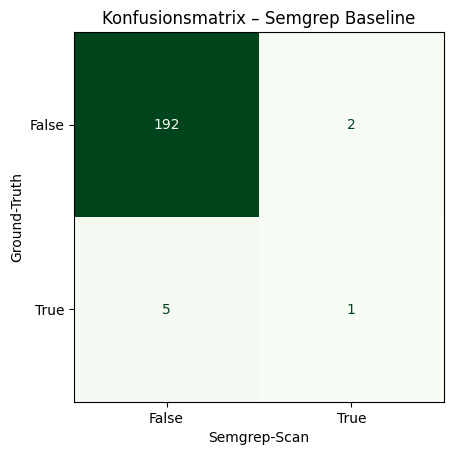

In [14]:
actual = vergleich['Vorhanden']
predicted = vergleich['semgrep_base_vulnerable']

cm = confusion_matrix(actual, predicted)

# Plot
cm_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["False", "True"])
cm_display.plot(cmap=plt.cm.Greens, colorbar=False)

plt.title("Konfusionsmatrix – Semgrep Baseline")
plt.xlabel("Semgrep-Scan")
plt.ylabel("Ground-Truth")
plt.show()

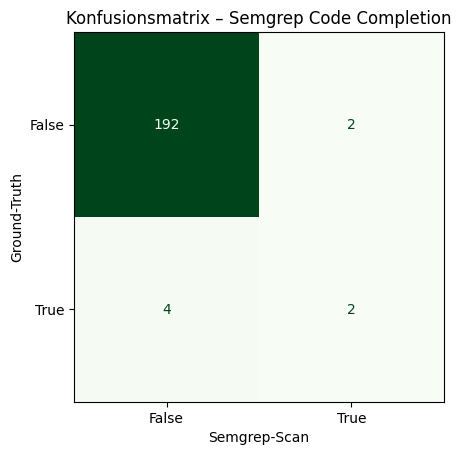

In [15]:
# 1. Daten definieren
actual = vergleich['Vorhanden']
predicted = vergleich['semgrep_comp_vulnerable']

# 2. Matrix berechnen (Ergebnis in 'cm' speichern, nicht in den Funktionsnamen!)
cm = confusion_matrix(actual, predicted)

# 3. Display erstellen und plotten
cm_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["False", "True"])
cm_display.plot(cmap=plt.cm.Greens, colorbar=False)

plt.title("Konfusionsmatrix – Semgrep Code Completion")
plt.xlabel("Semgrep-Scan")
plt.ylabel("Ground-Truth")
plt.show()

## Kapitel 6.4

### Manuelle Überprüfung bei CodeCompletion, ob dieser möglicherweise Fehler eingebaut hat
* 2478_Deep Dive Into Modern Web Development_osa0b_block_17.js:
    - weiterhin A01:2025 - Broken Access Control

* 26903_Learn Web Development_index_block_1.js: 
    - False Positive durch Semgrep
    - Code wurde nicht erweitert sondern nur 2 Zeilen an Kommentar eingefügt
    - Es gibt keine Veränderung am Code sondern nur ein `Komma` in Zeile 11

* 9501_Deep Dive Into Modern Web Development_part13a_block_15.js
    - In der Ground Truth + Semgrep Baseline Analyse als Sicherheitslücke gewertet
    - Sicherheitslücke wurde nicht behoben
    
* 9667_Deep Dive Into Modern Web Development_part5d_block_19.js
    - im Ground Truth war dies keine Sicherheitslücke
    - im Baseline Scan wurde dieser Auch nicht als Sicherheitslücke erkannt
    - Samgrep gibt als Confidence=low an, was darauf andeutet, dass die Software selber nicht genau weiß,
    ob Ergebnisse korrekt sind

In [15]:
df_semgrep_code_completion

,check_id,path,severity,message,start_line,start_col,end_line,end_col,lines,fingerprint,...,cwe_1,owasp_1,owasp_2,technology_1,technology_2,technology_3,vulnerability_class_1,references_1,references_2,references_3
0,javascript.express.security.audit.express-chec...,/Users/msyl16/Desktop/ai_semgrep_sicherheitslu...,INFO,A CSRF middleware was not detected in your exp...,2,7,2,22,requires login,requires login,...,CWE-352: Cross-Site Request Forgery (CSRF),A01:2021 - Broken Access Control,A01:2025 - Broken Access Control,javascript,typescript,express,Cross-Site Request Forgery (CSRF),https://www.npmjs.com/package/csurf,https://www.npmjs.com/package/csrf,https://cheatsheetseries.owasp.org/cheatsheets...
1,javascript.lang.security.audit.unsafe-formatst...,/Users/msyl16/Desktop/ai_semgrep_sicherheitslu...,INFO,Detected string concatenation with a non-liter...,12,7,12,78,requires login,requires login,...,CWE-134: Use of Externally-Controlled Format S...,A01:2021 - Broken Access Control,A01:2025 - Broken Access Control,javascript,None,None,Improper Validation,https://cwe.mitre.org/data/definitions/134.html,None,None
2,problem-based-packs.insecure-transport.js-node...,/Users/msyl16/Desktop/ai_semgrep_sicherheitslu...,WARNING,Checks for setting the environment variable NO...,6,10,9,6,requires login,requires login,...,None,None,None,node.js,None,None,Mishandled Sensitive Information,https://nodejs.org/api/https.html#https_https_...,https://stackoverflow.com/questions/20433287/n...,None
3,javascript.express.security.audit.express-chec...,/Users/msyl16/Desktop/ai_semgrep_sicherheitslu...,INFO,A CSRF middleware was not detected in your exp...,2,7,2,22,requires login,requires login,...,CWE-352: Cross-Site Request Forgery (CSRF),A01:2021 - Broken Access Control,A01:2025 - Broken Access Control,javascript,typescript,express,Cross-Site Request Forgery (CSRF),https://www.npmjs.com/package/csurf,https://www.npmjs.com/package/csrf,https://cheatsheetseries.owasp.org/cheatsheets...


In [ ]:
df_semgrep_baseline

## Kapitel 7.5

In [16]:
analyzer = code_directory_analyzer.CodeDirectoryAnalyzer()
analyzer

In [17]:
paths = df_semgrep_code_completion.path.to_list()

In [18]:
df_code_completion = (
    pd.DataFrame(
        analyzer
        .analyze_directory(
            path_of_data = "../data/CodeCompletion/"
        )
    )
)

In [23]:
print(df_code_completion["logical_lines_of_code"].describe())

count    200.000000
mean      26.260000
std       42.398948
min        2.000000
25%        8.750000
50%       16.000000
75%       29.250000
max      440.000000
Name: logical_lines_of_code, dtype: float64


In [22]:
print(df_sample["logical_lines_of_code"].describe())

count    200.000000
mean      19.230000
std       47.708991
min        0.000000
25%        4.000000
50%        7.500000
75%       14.000000
max      527.000000
Name: logical_lines_of_code, dtype: float64
